# Tutoriel Cartomize prétraitement et analyse Sentinel-2 L2A

**Objectif :** présenter un flux reproductible de préparation d’une scène Sentinel-2 L2A : vérification des métadonnées, diagnostic de couverture et de qualité, masquage des pixels non utilisables, calcul d’indices spectraux et production de statistiques spatiales.

Les métadonnées de provenance de la scène sont consignées dans `data/provenance.json`.

> L'emprise est une fenêtre d'analyse située à Kinshasa et non une limite administrative.

## 1. Données d’entrée et environnement

Le dossier `data` regroupe les bandes, le masque de qualité et les métadonnées nécessaires au traitement. Les empreintes SHA-256 permettent de contrôler l’intégrité des fichiers.

In [1]:
from pathlib import Path
import json, shutil
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPImage
import cartomize as cm

ROOT = Path.cwd()
if ROOT.name != "demonstration-carto":
    candidate = ROOT / "demonstration-carto"
    if candidate.is_dir():
        ROOT = candidate
DATA = ROOT / "data"
RESULTS = ROOT / "results"
if not (DATA / "provenance.json").is_file():
    raise FileNotFoundError("Données réelles absentes : exécuter download_real_data.py avant le notebook.")
if RESULTS.exists():
    shutil.rmtree(RESULTS)
RESULTS.mkdir()
provenance = json.loads((DATA / "provenance.json").read_text(encoding="utf-8"))
print("Scène :", provenance["selected_item_id"])
print("Date :", provenance["selected_datetime"])
print("Plateforme :", provenance["platform"])
print("Tuile MGRS :", provenance["mgrs_tile"])
print("Nuages déclarés :", provenance["global_cloud_cover_percent"], "%")
print("Pixels SCL utilisables sur l'emprise :", round(provenance["aoi_scl_usable_percent_before_processing"], 2), "%")

Scène : S2C_33MWR_20250819_0_L2A
Date : 2025-08-19T09:22:06.156000Z
Plateforme : sentinel-2c
Tuile MGRS : None
Nuages déclarés : 11.730018 %
Pixels SCL utilisables sur l'emprise : 100.0 %


## 2. Vérification des métadonnées

Le système de coordonnées, la résolution, le type numérique et les paramètres de calibration sont contrôlés avant le traitement.

In [2]:
scene = cm.load_scenes_manifest(DATA / "scenes.json")[0]
rows = []
for name, band in scene.bands.items():
    with rasterio.open(band.path) as src:
        rows.append({
            "bande": name,
            "fichier": Path(band.path).name,
            "largeur": src.width,
            "hauteur": src.height,
            "crs": str(src.crs),
            "resolution": src.res,
            "dtype": src.dtypes[0],
            "scale": band.scale,
            "offset": band.offset,
            "unite": band.unit,
        })
display(pd.DataFrame(rows))
print("Masque qualité :", Path(scene.quality).name, "|", scene.quality_kind)
print("Notes de calibration :")
for note in scene.notes:
    print("-", note)

,bande,fichier,largeur,hauteur,crs,resolution,dtype,scale,offset,unite
0,blue,B02.tif,667,664,EPSG:32733,"(10.0, 10.0)",uint16,0.0001,0.0,reflectance
1,green,B03.tif,667,664,EPSG:32733,"(10.0, 10.0)",uint16,0.0001,0.0,reflectance
2,red,B04.tif,667,664,EPSG:32733,"(10.0, 10.0)",uint16,0.0001,0.0,reflectance
3,nir,B08.tif,667,664,EPSG:32733,"(10.0, 10.0)",uint16,0.0001,0.0,reflectance
4,swir1,B11.tif,334,332,EPSG:32733,"(20.0, 20.0)",uint16,0.0001,0.0,reflectance


Masque qualité : SCL.tif | sentinel_scl
Notes de calibration :
- Earth Search COG harmonisé blue : scale déclaré=0.0001, offset déclaré=-0.1, offset effectif=0 ; earthsearch:boa_offset_applied=true, aucune seconde application du décalage BOA.
- Earth Search COG harmonisé green : scale déclaré=0.0001, offset déclaré=-0.1, offset effectif=0 ; earthsearch:boa_offset_applied=true, aucune seconde application du décalage BOA.
- Earth Search COG harmonisé red : scale déclaré=0.0001, offset déclaré=-0.1, offset effectif=0 ; earthsearch:boa_offset_applied=true, aucune seconde application du décalage BOA.
- Earth Search COG harmonisé nir : scale déclaré=0.0001, offset déclaré=-0.1, offset effectif=0 ; earthsearch:boa_offset_applied=true, aucune seconde application du décalage BOA.
- Earth Search COG harmonisé swir16 : scale déclaré=0.0001, offset déclaré=-0.1, offset effectif=0 ; earthsearch:boa_offset_applied=true, aucune seconde application du décalage BOA.


## 3. État initial de la zone avant diagnostic

Avant d’exécuter le diagnostic hybride, Cartomize conserve un candidat Sentinel-2 couvrant la même emprise mais de qualité inférieure. Cette acquisition sert uniquement à illustrer ce que le système doit détecter et rejeter ; elle n’est jamais utilisée comme produit scientifique final.

La zone d’étude est dessinée en rouge sur l’image initiale.

In [3]:
before_info = provenance["before_diagnostic"]
before_dir = DATA / "before_diagnostic"

def read_reflectance(path, scale=0.0001, offset=0.0):
    with rasterio.open(path) as src:
        arr = src.read(1).astype("float64")
        nodata = src.nodata
    valid = np.isfinite(arr)
    if nodata is not None:
        valid &= arr != nodata
    out = arr * scale + offset
    out[~valid] = np.nan
    return out

# Earth Search harmonized COGs have the BOA offset already applied.
blue0 = read_reflectance(before_dir / "B02.tif")
green0 = read_reflectance(before_dir / "B03.tif")
red0 = read_reflectance(before_dir / "B04.tif")

stack0 = np.dstack([red0, green0, blue0])
valid0 = np.isfinite(stack0).all(axis=2)
rgb0 = np.zeros((*stack0.shape[:2], 3), dtype="uint8")
for i in range(3):
    values = stack0[..., i][valid0]
    low, high = np.quantile(values, [0.02, 0.98])
    scaled = np.clip((stack0[..., i] - low) / max(high - low, 1e-9), 0, 1)
    rgb0[..., i] = np.nan_to_num(scaled * 255).astype("uint8")

aoi0 = gpd.read_file(DATA / "aoi.geojson")
with rasterio.open(before_dir / "B04.tif") as src:
    aoi_bounds = aoi0.to_crs(src.crs).total_bounds
    xmin, ymin, xmax, ymax = src.bounds

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(rgb0, extent=[xmin, xmax, ymin, ymax])
aoi_plot = aoi0.to_crs(src.crs)
aoi_plot.boundary.plot(ax=ax, linewidth=2)
ax.set_title(
    f"AVANT diagnostic — candidat {before_info['item_id']}\n"
    f"Nuages scène : {before_info['global_cloud_cover_percent']:.2f} % · "
    f"Qualité hybride AOI : {before_info['aoi_hybrid_usable_percent']:.2f} %"
)
ax.set_axis_off()
fig.tight_layout()
fig.savefig(RESULTS / "before_diagnostic.png", dpi=180, bbox_inches="tight")
plt.show()

display(pd.DataFrame([{
    "scene": before_info["item_id"],
    "date": before_info["datetime"],
    "nuages_scene_%": before_info["global_cloud_cover_percent"],
    "SCL_utilisable_AOI_%": before_info["aoi_scl_usable_percent"],
    "nuages_spectraux_AOI_%": before_info["aoi_spectral_cloud_percent"],
    "qualite_hybride_AOI_%": before_info["aoi_hybrid_usable_percent"],
    "decision": before_info["decision"],
}]))

,scene,date,nuages_scene_%,SCL_utilisable_AOI_%,nuages_spectraux_AOI_%,qualite_hybride_AOI_%,decision
0,S2B_33MWR_20250824_1_L2A,2025-08-24T09:21:48.561000Z,22.686391,2.094907,92.375047,1.02509,rejected_below_quality_threshold


![Zone avant diagnostic avec acquisition nuageuse candidate](./results/before_diagnostic.png)

## 4. Diagnostic de qualité et prétraitement automatique

Cartomize évalue la couverture et la qualité des pixels, applique la calibration déclarée, utilise la couche SCL pour identifier et masquer les pixels non utilisables, harmonise les grilles et découpe les données sur la zone d’étude. Le seuil minimal de couverture utile est fixé à 95 %.

In [4]:
prepared = cm.preprocess_imagery(
    DATA,
    RESULTS / "preprocessed",
    aoi=DATA / "aoi.geojson",
    band_order=["blue", "green", "red", "nir"],
    coverage_threshold=95,
    allow_partial=False,
    mask_clouds=True,
    mask_saturation=False,
    multiband=True,
    separate_bands=True,
    composition="natural",
)
print("Statut :", prepared.report["status"])
print("Scènes retenues :", prepared.report["selected_scene_ids"])
print("Couverture utile :", round(prepared.report["usable_percent"], 3), "%")
print("Mosaïque :", prepared.report["mosaic"])
print("Rapport :", prepared.manifest)
product = prepared.products[0]
display(pd.DataFrame([product]))
quality_rows = []
spectral_rows = []
for item in prepared.diagnostic.report.get("scenes", []):
    quality = item.get("quality_statistics")
    if quality:
        quality_rows.append({
            "scene": item["id"],
            "type_masque": quality["kind"],
            "pixels_nuageux_SCL": quality.get("cloud_pixels"),
            "nuages_SCL_%": quality.get("cloud_percent"),
            "SCL7_faible_proba": quality.get("cloud_low_probability_pixels"),
            "SCL8_moyenne_proba": quality.get("cloud_medium_probability_pixels"),
            "SCL9_haute_proba": quality.get("cloud_high_probability_pixels"),
            "cirrus": quality.get("cirrus_pixels"),
            "ombres": quality.get("cloud_shadow_pixels"),
            "neige": quality.get("snow_pixels"),
        })
    spectral = item.get("spectral_cloud_statistics")
    if spectral:
        spectral_rows.append({
            "scene": item["id"],
            "methode": spectral.get("method"),
            "pixels_evalues": spectral.get("evaluated_pixels"),
            "nuages_supplementaires": spectral.get("cloud_pixels"),
            "nuages_supplementaires_%": spectral.get("cloud_percent"),
            "pixels_clairs": spectral.get("clear_pixels"),
            "pixels_sans_diagnostic": spectral.get("nodata_pixels"),
        })
print("Diagnostic SCL officiel")
display(pd.DataFrame(quality_rows))
print("Détection spectrale supplémentaire")
display(pd.DataFrame(spectral_rows))
print("Pixels utilisables après combinaison des masques :", prepared.diagnostic.report["usable_pixels"])
print("Pixels rejetés au total :", prepared.diagnostic.report["present_pixels"] - prepared.diagnostic.report["usable_pixels"])


Statut : partial
Scènes retenues : ['S2C_33MWR_20250819_0_L2A']
Couverture utile : 99.998 %
Mosaïque : False
Rapport : /home/runner/work/cartomize-python/cartomize-python/demonstration-carto/results/preprocessed/preprocessing.json


,scenes,multiband,bands,composition,source_index,report
0,[S2C_33MWR_20250819_0_L2A],/home/runner/work/cartomize-python/cartomize-p...,"{'1': {'name': 'blue', 'path': '/home/runner/w...",/home/runner/work/cartomize-python/cartomize-p...,/home/runner/work/cartomize-python/cartomize-p...,/home/runner/work/cartomize-python/cartomize-p...


Diagnostic SCL officiel


,scene,type_masque,pixels_nuageux_SCL,nuages_SCL_%,SCL7_faible_proba,SCL8_moyenne_proba,SCL9_haute_proba,cirrus,ombres,neige
0,S2C_33MWR_20250819_0_L2A,sentinel_scl,132,0.029862,128,4,0,0,0,0


Détection spectrale supplémentaire


,scene,methode,pixels_evalues,nuages_supplementaires,nuages_supplementaires_%,pixels_clairs,pixels_sans_diagnostic
0,S2C_33MWR_20250819_0_L2A,sentinel_spectral_fallback_v1,442031,4,0.000905,442027,0


Pixels utilisables après combinaison des masques : 442023
Pixels rejetés au total : 8


### Diagnostic nuageux

Le masque final combine la couche SCL Sentinel-2 et, lorsque les bandes nécessaires sont disponibles, un contrôle spectral supplémentaire. Les deux sources restent rapportées séparément.

In [5]:
scene_report = prepared.diagnostic.report["scenes"][0]
with rasterio.open(scene_report["quality_mask"]) as src:
    scl_native = src.read(1)
with rasterio.open(scene_report["spectral_cloud_mask"]) as src:
    spectral_native = src.read(1, masked=True)
with rasterio.open(prepared.diagnostic.gaps) as src:
    gaps = src.read(1, masked=True)

scl_cloud = np.isin(scl_native, [7, 8, 9, 10])
spectral_cloud = np.ma.filled(spectral_native == 0, False)
final_rejection = np.ma.filled(gaps == 3, False)

fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
axes[0].imshow(scl_cloud, cmap="gray")
axes[0].set_title("Nuages signalés par SCL (7–10)")
axes[1].imshow(spectral_cloud, cmap="gray")
axes[1].set_title("Nuages supplémentaires — contrôle spectral")
axes[2].imshow(final_rejection, cmap="gray")
axes[2].set_title("Pixels finalement rejetés")
for ax in axes:
    ax.axis("off")
fig.savefig(RESULTS / "cloud_diagnostic.png", dpi=180, bbox_inches="tight")
plt.show()


![Diagnostic nuageux : SCL, contrôle spectral et masque final](./results/cloud_diagnostic.png)

## 5. Composition en couleurs naturelles

La composition est un produit de visualisation. Les analyses suivantes utilisent toujours le raster scientifique multibande.

In [6]:
composition = Path(product["composition"])
with rasterio.open(composition) as src:
    rgb = np.moveaxis(src.read()[:3], 0, -1)
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(rgb)
ax.set_title("Sentinel-2 L2A — composition naturelle après masque et découpage")
ax.axis("off")
fig.tight_layout()
fig.savefig(RESULTS / "natural_color.png", dpi=180, bbox_inches="tight")
plt.show()


### Composition naturelle produite

![Composition naturelle Sentinel-2 L2A](./results/natural_color.png)

### Comparaison visuelle avant / après

La comparaison ci-dessous oppose volontairement deux acquisitions sur **la même emprise** :
- à gauche, un candidat nuageux de qualité insuffisante avant sélection automatique ;
- à droite, la scène retenue et préparée par Cartomize après diagnostic hybride, masquage et découpage.

Il ne s’agit donc pas de prétendre que les nuages ont disparu de la même acquisition : Cartomize a d’abord diagnostiqué les candidats, rejeté les moins fiables, puis produit le résultat scientifique à partir de la meilleure acquisition disponible.

In [7]:
before_png = plt.imread(RESULTS / "before_diagnostic.png")
after_png = plt.imread(RESULTS / "natural_color.png")

fig, axes = plt.subplots(1, 2, figsize=(18, 7), constrained_layout=True)
axes[0].imshow(before_png)
axes[0].set_title(
    f"AVANT — candidat rejeté\n{before_info['item_id']} · "
    f"qualité hybride {before_info['aoi_hybrid_usable_percent']:.2f} %"
)
axes[1].imshow(after_png)
axes[1].set_title(
    f"APRÈS — scène retenue et traitée\n{provenance['selected_item_id']} · "
    f"pixels utilisables {prepared.report['usable_percent']:.3f} %"
)
for ax in axes:
    ax.axis("off")
fig.savefig(RESULTS / "before_after.png", dpi=180, bbox_inches="tight")
plt.show()

![Comparaison avant diagnostic et après traitement automatique](./results/before_after.png)

## 6. Indices spectraux

Calcul de trois indices à partir de la réflectance de surface calibrée :

- NDVI : végétation ;
- NDWI (McFeeters) : contraste eau / proche infrarouge ;
- EVI : végétation avec correction par le bleu et constante additive.

Les formules et références sont celles du registre Cartomize.

In [8]:
indices_path = cm.spectral_indices(
    product["multiband"],
    RESULTS / "indices.tif",
    indices=["NDVI", "NDWI", "EVI"],
)
definitions = {row["name"]: row for row in cm.list_indices()}
display(pd.DataFrame([
    {"indice": name, "formule": definitions[name]["formula"], "reference": definitions[name]["reference"]}
    for name in ("NDVI", "NDWI", "EVI")
]))

,indice,formule,reference
0,NDVI,(nir-red)/(nir+red),https://ntrs.nasa.gov/citations/19740022614
1,NDWI,(green-nir)/(green+nir),https://doi.org/10.1080/01431169608948714
2,EVI,g*(nir-red)/(nir+C1*red-C2*blue+L),https://doi.org/10.1016/S0034-4257(96)00112-5


In [9]:
stats = {}
with rasterio.open(indices_path) as src:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
    for band, name in enumerate(src.descriptions, 1):
        data = src.read(band, masked=True).astype("float64")
        valid = data.compressed()
        stats[name] = {
            "count": int(valid.size),
            "min": float(valid.min()),
            "max": float(valid.max()),
            "mean": float(valid.mean()),
            "std": float(valid.std()),
            "p05": float(np.quantile(valid, .05)),
            "p50": float(np.quantile(valid, .50)),
            "p95": float(np.quantile(valid, .95)),
        }
        view = axes[band-1].imshow(data, cmap="RdYlGn" if name != "NDWI" else "BrBG")
        axes[band-1].set_title(name)
        axes[band-1].axis("off")
        fig.colorbar(view, ax=axes[band-1], shrink=.75)
    fig.savefig(RESULTS / "indices.png", dpi=180, bbox_inches="tight")
display(pd.DataFrame(stats).T)
plt.show()


,count,min,max,mean,std,p05,p50,p95
NDVI,442023.0,-0.235546,0.640000,0.016901,0.153217,-0.176255,0.051710,0.275929
NDWI,442023.0,-0.604765,0.221358,-0.071791,0.155053,-0.310530,-0.116625,0.133501
EVI,442023.0,-0.091283,0.570322,0.023218,0.083471,-0.069625,0.029669,0.173066


### Cartes des indices spectraux

![Indices spectraux NDVI, NDWI et EVI](./results/indices.png)

## 7. Statistiques zonales NDVI

On utilise le polygone d'étude comme zone et le premier canal du raster d'indices, qui correspond à NDVI.

In [10]:
zonal = cm.raster.zonal_stats(
    indices_path,
    DATA / "aoi.geojson",
    band=1,
    prefix="ndvi_",
    include_coverage=True,
)
zonal.to_file(RESULTS / "ndvi_zonal.gpkg", driver="GPKG", index=False)
pd.DataFrame(zonal.drop(columns=zonal.geometry.name)).to_csv(RESULTS / "ndvi_zonal.csv", index=False)
display(zonal.drop(columns=zonal.geometry.name))

,name,scope,ndvi_count,ndvi_min,ndvi_max,ndvi_mean,ndvi_sum,ndvi_std,ndvi_zone_pixels,ndvi_raster_pixels,ndvi_coverage_percent
0,Fenêtre de démonstration Kinshasa,emprise d'analyse; pas une limite administrative,442023,-0.235546,0.64,0.016901,7470.604485,0.153217,442031,442031,99.99819


## 8. Répartition des classes SCL

Les codes SCL restent ceux du produit Sentinel-2 L2A. Ils ne sont pas renommés en classes d'occupation du sol.

,code,classe_SCL,pixels,percent,area_ha
0,4,Vegetation,25,0.022635,1.00
1,5,Not vegetated,69012,62.484268,2760.48
2,6,Water,41377,37.463218,1655.08
3,7,Unclassified,32,0.028973,1.28
4,8,Cloud medium probability,1,0.000905,0.04


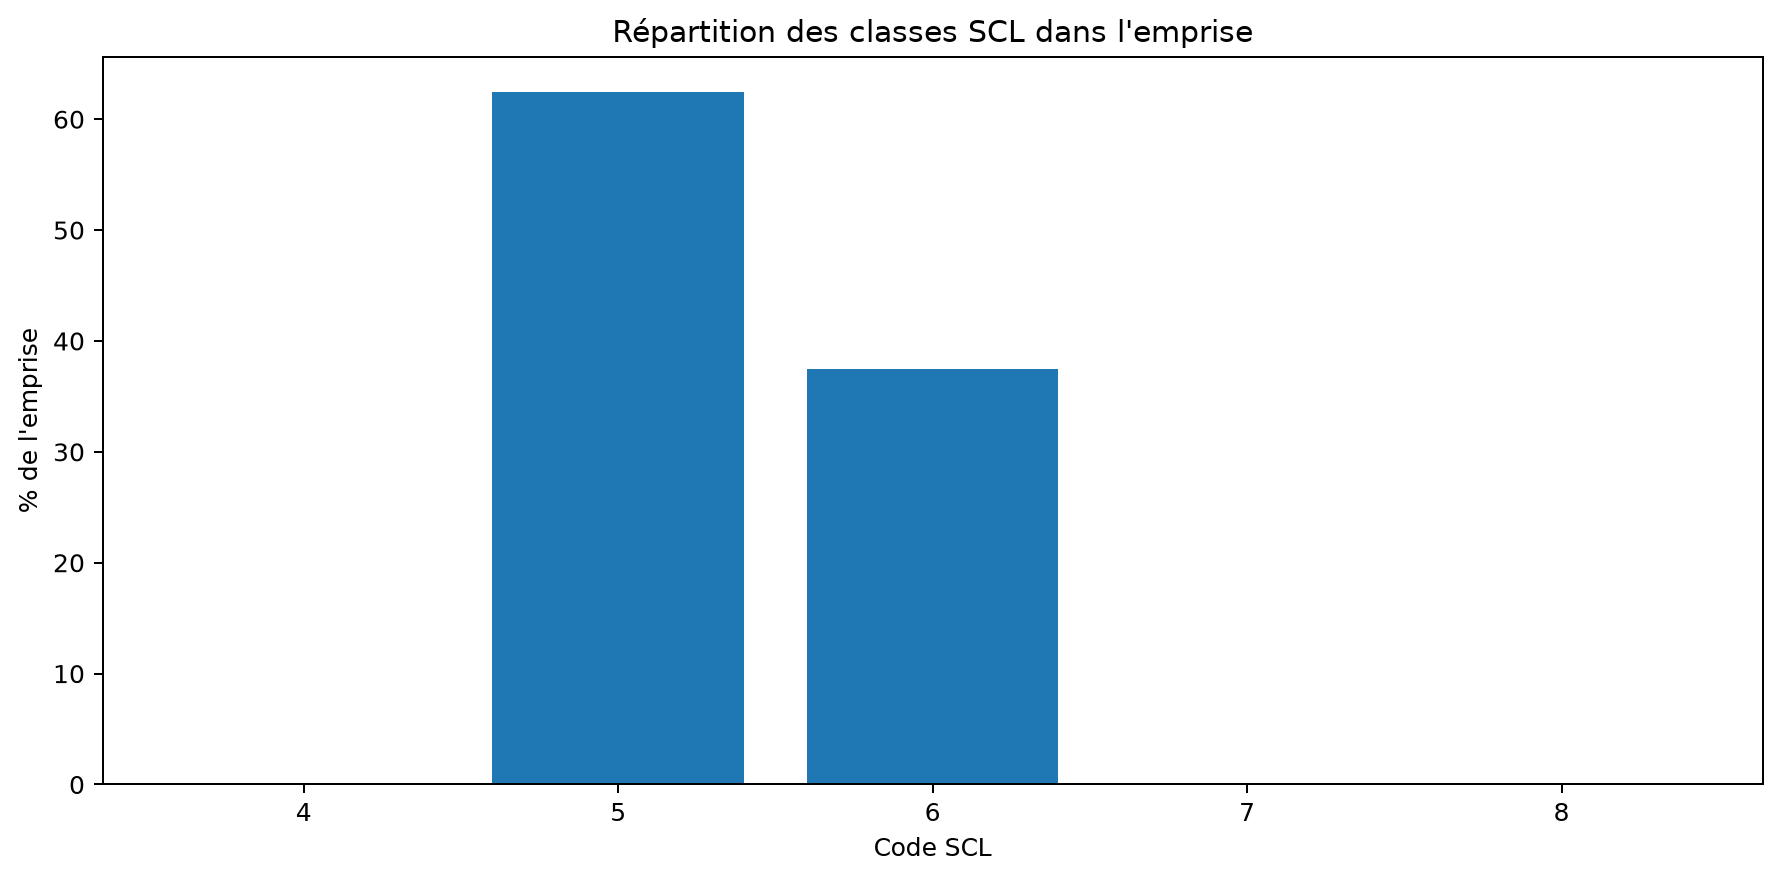

In [11]:
SCL_LABELS = {
    0: "No Data",
    1: "Saturated or defective",
    2: "Dark area pixels",
    3: "Cloud shadows",
    4: "Vegetation",
    5: "Not vegetated",
    6: "Water",
    7: "Unclassified",
    8: "Cloud medium probability",
    9: "Cloud high probability",
    10: "Thin cirrus",
    11: "Snow or ice",
}
aoi = gpd.read_file(DATA / "aoi.geojson")
with rasterio.open(DATA / "SCL.tif") as src:
    geom = [g.__geo_interface__ for g in aoi.to_crs(src.crs).geometry]
    arr, transform = mask(src, geom, crop=True, filled=False, indexes=1)
    values = arr.compressed().astype("int32")
    unique, counts = np.unique(values, return_counts=True)
    pixel_area_ha = abs(transform.a * transform.e) / 10000.0
scl = []
for value, count in zip(unique, counts):
    scl.append({
        "code": int(value),
        "classe_SCL": SCL_LABELS.get(int(value), f"Code {value}"),
        "pixels": int(count),
        "percent": float(100 * count / counts.sum()),
        "area_ha": float(count * pixel_area_ha),
    })
scl_df = pd.DataFrame(scl)
scl_df.to_csv(RESULTS / "scl_summary.csv", index=False)
display(scl_df)
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(scl_df["code"].astype(str), scl_df["percent"])
ax.set_xlabel("Code SCL")
ax.set_ylabel("% de l'emprise")
ax.set_title("Répartition des classes SCL dans l'emprise")
fig.tight_layout()
fig.savefig(RESULTS / "scl.png", dpi=180, bbox_inches="tight")
plt.show()
display(IPImage(filename=str(RESULTS / "scl.png")))


## 9. Portée de l’analyse

Ce tutoriel porte sur le prétraitement, le contrôle de qualité, les indices spectraux et les statistiques spatiales. Une classification supervisée nécessite des données de référence indépendantes ; une classification non supervisée produit des groupes spectraux qui doivent être validés avant toute interprétation thématique.

## 10. Traçabilité des résultats

Le fichier `metrics.json` regroupe les indicateurs calculés pendant l’exécution afin d’assurer la traçabilité des résultats.

In [12]:
metrics = {
    "schema": "cartomize.demonstration.metrics.v1",
    "scene": {
        "id": provenance["selected_item_id"],
        "datetime": provenance["selected_datetime"],
        "platform": provenance["platform"],
        "mgrs_tile": provenance["mgrs_tile"],
        "global_cloud_cover_percent": provenance["global_cloud_cover_percent"],
    },
    "preprocessing": {
        "status": prepared.report["status"],
        "usable_percent": float(prepared.report["usable_percent"]),
        "threshold_met": bool(prepared.report["threshold_met"]),
        "selected_scene_ids": prepared.report["selected_scene_ids"],
        "mosaic": bool(prepared.report["mosaic"]),
    },
    "indices": stats,
    "scl": scl,
    "cloud_diagnostics": {
        "scl": quality_rows,
        "spectral_fallback": spectral_rows,
        "usable_percent_after_combined_masks": float(prepared.report["usable_percent"]),
    },
    "before_after": {
        "before": before_info,
        "after": {
            "scene": provenance["selected_item_id"],
            "usable_percent": float(prepared.report["usable_percent"]),
        },
        "figure": "before_after.png",
    },
    "zonal_ndvi": pd.DataFrame(zonal.drop(columns=zonal.geometry.name)).to_dict(orient="records"),
    "products": {
        "multiband": str(Path(product["multiband"]).relative_to(RESULTS / "preprocessed")),
        "composition": str(Path(product["composition"]).relative_to(RESULTS / "preprocessed")),
        "indices": "indices.tif",
        "zonal": "ndvi_zonal.gpkg",
    },
}
(RESULTS / "metrics.json").write_text(json.dumps(metrics, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(metrics["preprocessing"], indent=2, ensure_ascii=False))

{
  "status": "partial",
  "usable_percent": 99.99819017218249,
  "threshold_met": true,
  "selected_scene_ids": [
    "S2C_33MWR_20250819_0_L2A"
  ],
  "mosaic": false
}


## 11. Utilisation dans l’interface de bureau

Le guide [GUIDE_INTERFACE.md](GUIDE_INTERFACE.md) présente les opérations correspondantes dans l’application de bureau.